# 0. Data Preparation: NEA Historical Rainfall

This notebook inspects and cleans the raw NEA rainfall datasets for 2017–2024 using PySpark. It examines the columns, data types, rainfall values, and completeness of records across stations and years to identify data quality issues. It then applies and documents the necessary cleaning steps and saves a cleaned dataset for use in Task 1 and Task 2.

## 0.1 Spark Session

In [18]:
import socket
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession

In [2]:
spark = SparkSession.builder.getOrCreate()

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-ashley-1-m
Spark master:  yarn
Spark version: 3.5.3


In [3]:
!gcloud storage ls gs://dsa5208-rainfall-sixing-data/raw/

gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2017).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2018).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2019).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2020).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2021).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2022).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2023).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2024).csv


## 0.2 Reading the Raw Rainfall Files (2017–2024)

In [4]:
DATA = "gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore*.csv"

rain = spark.read.csv(DATA, header=True)


## 0.3 Inspecting the Schema and Sample Data

This section examines the column names, data types, and sample records in the raw rainfall datasets to understand how the data is structured and identify any formatting or data type issues that may require cleaning.

In [5]:
# Inspect column names and data types
rain.printSchema()

# Display 10 sample records
rain.show(10, truncate=False)

# Dataset size
print(f"Number of rows: {rain.count():,}")
print(f"Number of columns: {len(rain.columns)}")


root
 |-- date: string (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- update_timestamp: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: string (nullable = true)
 |-- location_latitude: string (nullable = true)
 |-- reading_update_timestamp: string (nullable = true)
 |-- reading_value: string (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)

+----------+-------------------------+-------------------------+----------+----------------------+-----------------+------------------+-----------------+-------------------------+-------------+-----------------------------+------------+
|date      |timestamp                |update_timestamp         |station_id|station_name          |station_device_id|location_longitude|location_latitude|reading_update_timestamp |reading_value|reading_type    

Number of rows: 48,538,713
Number of columns: 12


- The dataset contains **48,538,713 rows and 12 columns**.
- All columns are strings; dates, timestamps, rainfall values, and coordinates require type conversion.
- The sample shows different stations at the same timestamp, all recording **0.0 mm** of rainfall.
- All columns allow null values; further checks are needed to identify actual missing values.

## 0.4 Converting Data Types

All columns were loaded as strings. Convert them to suitable types to support accurate filtering, calculations, and time-based analysis:

- Convert dates and timestamps to date/time types, using Singapore Time.
- Convert rainfall readings and coordinates to numeric types.
- Keep station identifiers and descriptive fields as strings.

In [6]:
from pyspark.sql import functions as F

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

rain = (
    rain
    .withColumn("date", F.to_date("date", "yyyy-MM-dd"))
    .withColumn("timestamp", F.to_timestamp("timestamp"))
    .withColumn("update_timestamp", F.to_timestamp("update_timestamp"))
    .withColumn(
        "reading_update_timestamp",
        F.to_timestamp("reading_update_timestamp")
    )
    .withColumn("reading_value", F.col("reading_value").cast("double"))
    .withColumn("location_latitude", F.col("location_latitude").cast("double"))
    .withColumn("location_longitude", F.col("location_longitude").cast("double"))
)

# Verify the updated schema and sample records
rain.printSchema()
rain.show(5, truncate=False)

root
 |-- date: date (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- update_timestamp: timestamp (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: double (nullable = true)
 |-- location_latitude: double (nullable = true)
 |-- reading_update_timestamp: timestamp (nullable = true)
 |-- reading_value: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)

+----------+-------------------+-------------------+----------+-------------------+-----------------+------------------+-----------------+------------------------+-------------+-----------------------------+------------+
|date      |timestamp          |update_timestamp   |station_id|station_name       |station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type                 |reading_uni

## 0.5 Checking Missing Values
Check all columns for null values, text columns for blanks and missing-value markers, and numeric columns for NaN values.

In [7]:
from pyspark.sql import functions as F
rain.select([

    F.sum(F.col(c).isNull().cast("long")).alias(c)
    for c in rain.columns
]).show(truncate = False)

+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+
|date|timestamp|update_timestamp|station_id|station_name|station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type|reading_unit|
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+
|0   |0        |0               |0         |0           |0                |0                 |0                |0                       |0            |0           |0           |
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+



All 12 columns contain **zero null values**. This confirms that no nulls are present in the current dataset, but separate checks are needed for blank strings, text markers such as "NA", numeric NaN values, and missing observation records.

In [8]:
string_cols = [
    name for name, dtype in rain.dtypes
    if dtype == "string"
]

rain.select([
    F.sum(
        F.upper(F.trim(F.col(c)))
        .isin("", "NA", "N/A", "NULL", "NONE", "NAN")
        .cast("long")
    ).alias(c)
    for c in string_cols
]).show(truncate=False)

+----------+------------+-----------------+------------+------------+
|station_id|station_name|station_device_id|reading_type|reading_unit|
+----------+------------+-----------------+------------+------------+
|0         |0           |0                |0           |0           |
+----------+------------+-----------------+------------+------------+



All string columns were checked for blank or whitespace-only values and common missing-value placeholders (`NA`, `N/A`, `NULL`, `NONE`, and `NAN`). Values were trimmed and converted to uppercase before comparison to account for extra spaces and differences in letter case. The results showed zero matches across all 12 columns.

## 0.6 Checking Duplicates

Duplicates are checked at two levels: identical records across all columns and repeated observations for the same station and timestamp. These checks help identify records that could cause rainfall to be counted more than once.

### 0.6.1 Checking Exact Duplicate Rows

Rows are grouped by all columns, and the number of occurrences of each unique row is counted. Groups with more than one occurrence indicate exact duplicates.

In [11]:
exact_duplicate_rows= (
    rain.groupBy(*rain.columns)
            .count()
            .filter(F.col("count") > 1)

)

exact_duplicate_rows.show(20, truncate=False)


+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+-----+
|date|timestamp|update_timestamp|station_id|station_name|station_device_id|location_longitude|location_latitude|reading_update_timestamp|reading_value|reading_type|reading_unit|count|
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+-----+
+----+---------+----------------+----------+------------+-----------------+------------------+-----------------+------------------------+-------------+------------+------------+-----+



The check returned no rows, indicating that no exact duplicate records were found across all columns.

### 0.6.2 Checking Repeated Station–Timestamp Combinations

Previously, we checked for rows that match across all columns. Now, we check whether the same station has multiple records for the same five-minute observation time, even if other fields differ. This helps flag possible double-counting of rainfall.

In [12]:
repeated_station_timestamps = (
    rain.select("station_id", "timestamp")
        .groupBy("station_id", "timestamp")
        .count()
        .filter(F.col("count") > 1)
)

repeated_station_timestamps.show(20, truncate=False)

+----------+---------+-----+
|station_id|timestamp|count|
+----------+---------+-----+
+----------+---------+-----+



No repeated station–timestamp combinations were found. Each station has at most one record for any given observation timestamp.

## 0.7 Exploring Column Distributions

Columns are grouped by their data type and meaning to examine rainfall values, station frequencies, geographic locations, observation and update times, and measurement types and units. These summaries help identify patterns, unusual values and inconsistencies in the dataset.

### 0.7.1 Rainfall Distribution

The distribution of `reading_value` is summarised using the minimum, maximum, mean, standard deviation and selected percentiles. These statistics describe the range and variability of five-minute rainfall amounts, including zero-rainfall readings.

In [17]:
rain.agg(
    F.min("reading_value").alias("min_rainfall"),
    F.max("reading_value").alias("max_rainfall"),
    F.mean("reading_value").alias("mean_rainfall"),
    F.stddev("reading_value").alias("stddev_rainfall"),
    F.percentile_approx("reading_value", 0.25).alias("p25"),
    F.percentile_approx("reading_value", 0.50).alias("median"),
    F.percentile_approx("reading_value", 0.75).alias("p75"),
    F.percentile_approx("reading_value", 0.95).alias("p95"),
    F.percentile_approx("reading_value", 0.99).alias("p99")
).show(truncate=False)

+------------+------------+--------------------+-------------------+---+------+---+---+---+
|min_rainfall|max_rainfall|mean_rainfall       |stddev_rainfall    |p25|median|p75|p95|p99|
+------------+------------+--------------------+-------------------+---+------+---+---+---+
|0.0         |37.2        |0.025303765871176602|0.27499070426794003|0.0|0.0   |0.0|0.0|0.6|
+------------+------------+--------------------+-------------------+---+------+---+---+---+



- Five-minute rainfall ranges from **0 to 37.2 mm**.
- Mean rainfall is **0.0253 mm**, with a standard deviation of **0.2750 mm**.
- The approximate **95th percentile is 0 mm**, suggesting roughly 95% or more of readings record no rainfall.
- The approximate **99th percentile is 0.6 mm**.
- The distribution is **strongly right-skewed**, dominated by dry intervals with relatively few large readings.
- The maximum of **37.2 mm** should be investigated before being classified as an error.

Next, we plot the distribution of positive five-minute rainfall amounts, excluding zero readings to examine rainfall patterns during wet intervals.

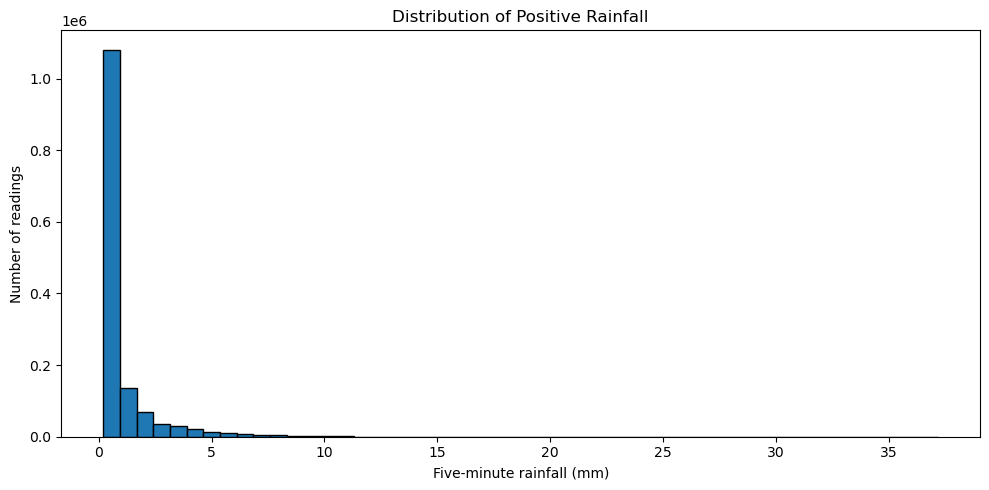

In [19]:
positive_pd = (
    rain.select("reading_value")
        .filter(F.col("reading_value") > 0)
        .toPandas()
)

plt.figure(figsize=(10, 5))
plt.hist(positive_pd["reading_value"], bins=50, edgecolor="black")
plt.title("Distribution of Positive Rainfall")
plt.xlabel("Five-minute rainfall (mm)")
plt.ylabel("Number of readings")
plt.tight_layout()
plt.show()

- Positive rainfall is **strongly right-skewed**, with most readings concentrated at low rainfall amounts.
- The frequency decreases rapidly as rainfall increases, indicating that large five-minute rainfall amounts are relatively rare.
- The long right tail extends to **37.2 mm**, although the largest readings are difficult to see on this scale.
- Even after excluding zero readings, small rainfall amounts dominate the distribution.

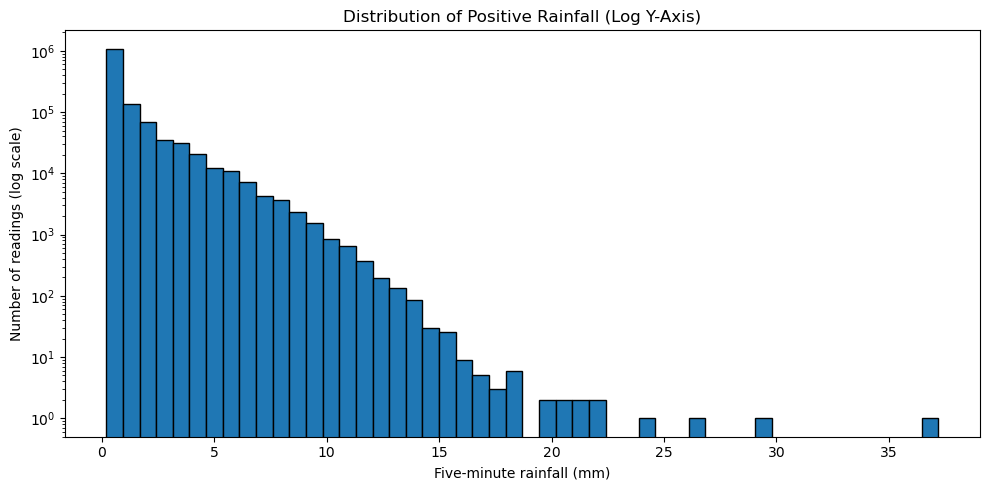

In [20]:
plt.figure(figsize=(10, 5))
plt.hist(positive_pd["reading_value"], bins=50, edgecolor="black")

plt.yscale("log")
plt.title("Distribution of Positive Rainfall (Log Y-Axis)")
plt.xlabel("Five-minute rainfall (mm)")
plt.ylabel("Number of readings (log scale)")

plt.tight_layout()
plt.show()

- The logarithmic y-axis reveals rare, large rainfall readings that were difficult to see in the original histogram.
- Counts generally decrease as rainfall amounts increase, confirming a strongly right-skewed distribution.
- Readings above **20 mm per five-minute interval** are very rare, with only a few observations in the visible bins.
- The isolated readings near **30–37.2 mm** warrant investigation, but the histogram alone does not establish that they are errors.

### 0.7.2 Station and Device Distribution

Distinct station IDs, station names and device IDs are examined, along with their record counts, to understand station coverage and identify differences in the number of observations.

In [21]:
rain.agg(
    F.countDistinct("station_id").alias("n_station_id"),
    F.countDistinct("station_name").alias("n_station_name"),
    F.countDistinct("station_device_id").alias("n_device_id"),
).show()

+------------+--------------+-----------+
|n_station_id|n_station_name|n_device_id|
+------------+--------------+-----------+
|          91|           117|         91|
+------------+--------------+-----------+



In [23]:
station_cols = ["station_id", "station_name", "station_device_id"]

for c in station_cols:
    print(f"Record counts by {c}")

    (
        rain.groupBy(c)
            .count()
            .orderBy(F.desc("count"))
            .show(100, truncate=False)
    )

Record counts by station_id


+----------+------+
|station_id|count |
+----------+------+
|S81       |808381|
|S77       |807540|
|S78       |806996|
|S88       |803891|
|S90       |801881|
|S113      |801783|
|S900      |801245|
|S43       |801008|
|S94       |800299|
|S89       |800048|
|S24       |798983|
|S40       |795387|
|S107      |794533|
|S119      |791256|
|S79       |790244|
|S08       |787572|
|S66       |786621|
|S50       |784187|
|S116      |783256|
|S121      |779986|
|S33       |779417|
|S114      |777971|
|S35       |775748|
|S123      |771930|
|S115      |771482|
|S112      |763679|
|S104      |762063|
|S84       |760510|
|S44       |759978|
|S69       |756031|
|S71       |751768|
|S109      |750767|
|S120      |733368|
|S111      |721853|
|S118      |688316|
|S215      |671916|
|S100      |621234|
|S106      |620780|
|S108      |606751|
|S117      |568651|
|S07       |554703|
|S64       |540807|
|S60       |535486|
|S82       |494758|
|S11       |472193|
|S220      |470307|
|S208      |470297|


+---------------------------+------+
|station_name               |count |
+---------------------------+------+
|Upper Changi Road North    |831631|
|Punggol Central            |808381|
|Alexandra Road             |807540|
|Poole Road                 |806996|
|Toa Payoh North            |803891|
|Bukit Timah Road           |801881|
|Marine Parade Road         |801783|
|Seletar Aerospace View     |801245|
|Kim Chuan Road             |801008|
|Pasir Ris Street 51        |800299|
|Tuas Road                  |800048|
|Mandai Lake Road           |795387|
|East Coast Parkway         |794533|
|Nicoll Highway             |791256|
|Somerset Road              |790244|
|Upper Thomson Road         |787572|
|Kranji Way                 |786621|
|Clementi Road              |784187|
|West Coast Highway         |783256|
|Old Choa Chu Kang Road     |779986|
|Jurong Pier Road           |779417|
|Choa Chu Kang Avenue 4     |777971|
|Old Toh Tuck Road          |775748|
|Towner Road                |771930|
|

+-----------------+------+
|station_device_id|count |
+-----------------+------+
|S81              |808381|
|S77              |807540|
|S78              |806996|
|S88              |803891|
|S90              |801881|
|S113             |801783|
|S900             |801245|
|S43              |801008|
|S94              |800299|
|S89              |800048|
|S24              |798983|
|S40              |795387|
|S107             |794533|
|S119             |791256|
|S79              |790244|
|S08              |787572|
|S66              |786621|
|S50              |784187|
|S116             |783256|
|S121             |779986|
|S33              |779417|
|S114             |777971|
|S35              |775748|
|S123             |771930|
|S115             |771482|
|S112             |763679|
|S104             |762063|
|S84              |760510|
|S44              |759978|
|S69              |756031|
|S71              |751768|
|S109             |750767|
|S120             |733368|
|S111             |721853|
|